<a href="https://colab.research.google.com/github/yuniecorn-dev/esaa_assignment2/blob/main/ESAA_OB_WEEK12_study_1120.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. GRU

### 개념 및 LSTM과의 차이점
* 게이트 메커니즘을 적용해 기울기 소멸 문제를 방지하는 RNN 변형 모델이며 **LSTM보다 구조가 간단**함
* LSTM의 망각 게이트와 입력 게이트를 하나로 합치고 별도의 **업데이트 게이트**로 구성됨
* 하나의 게이트 컨트롤러가 망각·입력을 동시에 제어함 (`1` 출력 시 망각 게이트 열림/입력 게이트 닫힘, `0` 출력 시 망각 게이트 닫힘/입력 게이트 열림)
* 별도의 셀 상태($c_t$)와 출력 게이트가 없어 전체 상태 벡터가 매 단계마다 출력됨

### GRU 내부 구조 및 연산 흐름
* **망각 게이트(Reset Gate)**
  * 과거 정보를 적당히 초기화(reset)하기 위해 시그모이드($\sigma$) 출력(0~1)을 이전 은닉 상태에 곱함
  * 수식 $r_t = \sigma(W_r \cdot [h_{t-1}, x_t])$
* **업데이트 게이트(Update Gate)**
  * 과거 정보와 현재 정보의 최신화 비율을 결정함
  * 시그모이드 출력($z_t$)은 현시점 정보량을 결정하고, $(1 - z_t)$는 직전 은닉층 정보에 곱해 과거 정보량을 결정함
  * 수식 $z_t = \sigma(W_z \cdot [h_{t-1}, x_t])$
* **후보군 및 은닉층 계산**
  * 과거 은닉층 정보를 그대로 쓰지 않고 망각 게이트 결과($r_t$)를 반영해 현시점 정보 후보군($\tilde{h}_t$)을 계산함
  * 업데이트 게이트 결과와 후보군을 결합해 최종 은닉 상태($h_t$)를 도출함
  * 수식 $\tilde{h}_t = \tanh(W \cdot [r_t * h_{t-1}, x_t])$, $h_t = (1 - z_t) * h_{t-1} + z_t \times \tilde{h}_t$

### GRU 실습 예제 핵심 및 결과
* **GRU 셀 구현 (MNIST 손글씨 분류)**
  * 선형 계층 출력 크기에 `3 * hidden_size`를 곱하는 이유는 망각 게이트, 입력 게이트, 그리고 $\tanh$가 적용되는 **새로운 게이트(newgate)** 총 3개로 쪼개기 위함임
  * 테스트 정확도 98%로 LSTM 셀과 유사한 성능을 보임
* **GRU 계층 구현 (스타벅스 주가 및 거래량 예측)**
  * 셀 상태(`c_0`) 없이 은닉 상태(`h_0`)만 초기화하여 학습을 진행함
  * 수치상 예측 정확도는 LSTM과 유사하나, 시각화 그래프상으로는 GRU 계층이 LSTM보다 실제 추세를 더 잘 따라가는 모습을 보임

In [ ]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
import torchvision.datasets as dataset
from torch.autograd import Variable
from torch.nn import Parameter
from torch import Tensor
import torch.nn.functional as F
from torch.utils.data import DataLoader
import math

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
cuda = True if torch.cuda.is_available() else False

Tensor = torch.cuda.FloatTensor if cuda else torch.FloatTensor

torch.manual_seed(125)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(125)

In [ ]:
mnist_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (1.0,))
])

In [ ]:
from torchvision.datasets import MNIST
download_root = '../chap07/MNIST_DATASET'

train_dataset = MNIST(download_root, transform=mnist_transform, train=True,
                      download=True)
valid_dataset = MNIST(download_root, transform=mnist_transform, train=False,
                      download=True)
test_dataset = MNIST(download_root, transform=mnist_transform, train=False,
                     download=True)

In [ ]:
batch_size = 64
train_loader = DataLoader(dataset= train_dataset,
                          batch_size=batch_size,
                          shuffle=True)
valid_loader = DataLoader(dataset= valid_dataset,
                          batch_size=batch_size,
                          shuffle=True)
test_loader = DataLoader(dataset= test_dataset,
                         batch_size=batch_size,
                         shuffle=False)

In [ ]:
batch_size = 100
n_iters = 6000
num_epochs = n_iters / (len(train_dataset) / batch_size)
num_epochs = int(num_epochs)

In [ ]:
class GRUCell(nn.Module):
    def __init__(self, input_size, hidden_size, bias=True):
        super(GRUCell, self).__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.bias = bias
        self.x2h = nn.Linear(input_size, 3 * hidden_size, bias=bias)
        self.h2h = nn.Linear(hidden_size, 3 * hidden_size, bias=bias)
        self.reset_parameters()

    def reset_parameters(self):  # 파라미터를 초기화
        std = 1.0 / math.sqrt(self.hidden_size)
        for w in self.parameters():
            w.data.uniform_(-std, std)

    def forward(self, x, hidden):
        x = x.view(-1, x.size(1))

        gate_x = self.x2h(x)  # LSTM 셀에서는 gates를 x2h+h2h로 정의했지만
                              # GRU 셀에서는 개별적이 상태를 유지합니다.
        gate_h = self.h2h(hidden)

        gate_x = gate_x.squeeze()
        gate_h = gate_h.squeeze()

        i_r, i_i, i_n = gate_x.chunk(3, 1) # 총 세 개의 게이트(망각, 입력, 새로운 게이트)를 위해
                                           # 세 개로 쪼갭니다.
        h_r, h_i, h_n = gate_h.chunk(3, 1)

        resetgate = F.sigmoid(i_r + h_r)
        inputgate = F.sigmoid(i_i + h_i)
        newgate = F.tanh(i_n + (resetgate * h_n)) # '새로운 게이트'는 탄젠트 활성화 함수가
                                                  # 적용된 게이트

        hy = newgate +inputgate * (hidden - newgate)
        return hy

In [ ]:
class GRUModel(nn.Module):
    def __init__(self, input_dim, hidden_dim, layer_dim, output_dim, bias=True):
      super(GRUModel, self).__init__()
      self.hidden_dim = hidden_dim
      self.layer_dim = layer_dim

      self.gru_cell = GRUCell(input_dim, hidden_dim, layer_dim) # 앞에서 정의한 GRUCell 함수를 불러옵니다.
      self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
      if torch.cuda.is_available():
        h0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim).cuda())
      else:
        h0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim))

      outs = []
      hn = h0[0,:,:] # LSTM 셀에서는 셀 상태에 대해서도 정의했었지만 GRU 셀에서는 셀은 사용되지 않습니다.

      for seq in range(x.size(1)):
        hn = self.gru_cell(x[:,seq,:], hn)
        outs.append(hn)
        out = outs[-1].squeeze()
        out = self.fc(out)
        return out

In [ ]:
input_dim = 28
hidden_dim = 128
layer_dim = 1
output_dim = 10

model = GRUModel(input_dim, hidden_dim, layer_dim, output_dim)

if torch.cuda.is_available():
  model.cuda()

criterion = nn.CrossEntropyLoss()
learning_rate = 0.1
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

In [ ]:
seq_dim = 28
loss_list = []
iter = 0
for epoch in range(num_epochs):
  for i, (images, labels) in enumerate(train_loader):
    if torch.cuda.is_available():
      images = Variable(images.view(-1, seq_dim, input_dim).cuda())
      labels = Variable(labels.cuda())
    else:
      images = Variable(images.view(-1, seq_dim, input_dim))
      labels = Variable(labels)

    optimizer.zero_grad()
    outputs = model(images)
    loss = criterion(outputs, labels)

    if torch.cuda.is_available():
      loss.cuda()

    loss.backward()
    optimizer.step()

    loss_list.append(loss.item())
    iter += 1

    if iter % 500 == 0:
      correct = 0
      total = 0
      for images, labels in valid_loader:
        if torch.cuda.is_available():
          images = Variable(images.view(-1, seq_dim, input_dim).cuda())
        else:
          images = Variable(images.view(-1, seq_dim, input_dim))

        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)

        if torch.cuda.is_available():
          correct += (predicted.cpu() == labels.cpu()).sum()
        else:
          correct += (predicted == labels).sum()

      accuracy = 100 * correct / total
      print('Iteration: {}. Loss: {}. Accuracy: {}'.format(iter, loss.item(), accuracy))

Iteration: 500. Loss: 2.3020684719085693. Accuracy: 10.319999694824219
Iteration: 1000. Loss: 2.310199499130249. Accuracy: 11.350000381469727
Iteration: 1500. Loss: 2.306101083755493. Accuracy: 11.350000381469727
Iteration: 2000. Loss: 2.300555944442749. Accuracy: 11.350000381469727
Iteration: 2500. Loss: 2.2927582263946533. Accuracy: 11.350000381469727
Iteration: 3000. Loss: 2.309049606323242. Accuracy: 11.350000381469727
Iteration: 3500. Loss: 2.3057706356048584. Accuracy: 11.350000381469727
Iteration: 4000. Loss: 2.304710865020752. Accuracy: 11.350000381469727
Iteration: 4500. Loss: 2.3079323768615723. Accuracy: 11.350000381469727
Iteration: 5000. Loss: 2.2947354316711426. Accuracy: 11.350000381469727
Iteration: 5500. Loss: 2.2989981174468994. Accuracy: 11.350000381469727
Iteration: 6000. Loss: 2.3024723529815674. Accuracy: 11.350000381469727
Iteration: 6500. Loss: 2.3102259635925293. Accuracy: 11.350000381469727
Iteration: 7000. Loss: 2.3134262561798096. Accuracy: 11.35000038146972

In [ ]:
def evaluate(model, val_iter):
  corrects, total, total_loss = 0, 0, 0
  model.eval()
  for images, labels in val_iter:
    if torch.cuda.is_available():
      images = Variable(images.view(-1, seq_dim, input_dim).cuda())
    else:
      images = Variable(images.view(-1, seq_dim, input_dim)).to(device)

    logit = model(images).to(device)
    loss = F.cross_entropy(logit, labels, reduction="sum")
    _, predicted = torch.max(logit.data, 1)
    total += labels.size(0)
    total_loss += loss.item()
    corrects += (predicted == labels).sum()

  avg_loss = total_loss / len(val_iter.dataset)
  avg_accuracy = corrects / total
  return avg_loss, avg_accuracy

In [ ]:
test_loss, test_acc = evaluate(model, test_loader)
print("Test Loss: %5.2f | Test Accuracy: %5.2f" % (test_loss, test_acc))

Test Loss:  2.30 | Test Accuracy:  0.11


### 3) GRU 계층 구현



In [ ]:
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.autograd import Variable
from tqdm import tqdm_notebook
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

In [ ]:
!git clone https://github.com/gilbutITbook/080289.git ### 추가 ###

fatal: destination path '080289' already exists and is not an empty directory.


In [ ]:
data = pd.read_csv('/content/080289//chap07/data/SBUX.csv')
print(data.dtypes)

Date          object
Open         float64
High         float64
Low          float64
Close        float64
Adj Close    float64
Volume         int64
dtype: object


In [ ]:
data['Date'] = pd.to_datetime(data['Date'])
data.set_index('Date', inplace=True)
data['Volume'] = data['Volume'].astype(float)

In [ ]:
X = data.iloc[:, :-1]
y = data.iloc[:, 5:6]
print(X)
print(y)

                  Open        High         Low       Close   Adj Close
Date                                                                  
2019-12-11   86.260002   86.870003   85.849998   86.589996   84.145752
2019-12-12   88.000000   88.889999   87.540001   88.209999   85.720032
2019-12-13   88.019997   88.790001   87.580002   88.669998   86.167046
2019-12-16   89.139999   89.300003   88.430000   88.779999   86.273941
2019-12-17   88.870003   88.970001   87.470001   88.129997   85.642288
...                ...         ...         ...         ...         ...
2020-12-04  101.349998  102.940002  101.070000  102.279999  101.442787
2020-12-07  102.010002  102.220001  100.690002  101.410004  100.579918
2020-12-08  100.370003  101.570000  100.010002  101.209999  100.381554
2020-12-09  101.940002  102.209999  100.099998  100.400002   99.578186
2020-12-10  103.510002  106.089996  102.750000  105.389999  104.527336

[253 rows x 5 columns]
                Volume
Date                  
2019-12

In [ ]:
ms = MinMaxScaler()
ss = StandardScaler()

X_ss = ss.fit_transform(X)
y_ms = ms.fit_transform(y)

X_train = X_ss[:200, :]
X_test = X_ss[200:, :]

y_train = y_ms[:200, :]
y_test = y_ms[200:, :]

print("Training Shape", X_train.shape, y_train.shape)
print("Testing Shape", X_test.shape, y_test.shape)

Training Shape (200, 5) (200, 1)
Testing Shape (53, 5) (53, 1)


In [ ]:
X_train_tensors = Variable(torch.Tensor(X_train))
X_test_tensors = Variable(torch.Tensor(X_test))

y_train_tensors = Variable(torch.Tensor(y_train))
y_test_tensors = Variable(torch.Tensor(y_test))

X_train_tensors_f = torch.reshape(X_train_tensors, (X_train_tensors.shape[0],
                                                   1, X_train_tensors.shape[1]))
X_test_tensors_f = torch.reshape(X_test_tensors, (X_test_tensors.shape[0],
                                                  1, X_test_tensors.shape[1]))

print("Training Shape", X_train_tensors_f.shape, y_train_tensors.shape)
print("Testing Shape", X_test_tensors_f.shape, y_test_tensors.shape)

Training Shape torch.Size([200, 1, 5]) torch.Size([200, 1])
Testing Shape torch.Size([53, 1, 5]) torch.Size([53, 1])


In [ ]:
class GRU(nn.Module):
  def __init__(self, num_classes, input_size, hidden_size, num_layers, seq_length):
    super(GRU, self).__init__()
    self.num_classes = num_classes
    self.num_layers = num_layers
    self.input_size = input_size
    self.hidden_size = hidden_size
    self.seq_length = seq_length

    self.gru = nn.GRU(input_size=input_size, hidden_size=hidden_size,
                      num_layers=num_layers, batch_first=True)
    self.fc_1 = nn.Linear(hidden_size, 128)
    self.fc = nn.Linear(128, num_classes)
    self.relu = nn.ReLU()

  def forward(self, x):
    h_0 = Variable(torch.zeros(self.num_layers, x.size(0), self.hidden_size))
    output, (hn) = self.gru(x, h_0)
    hn = hn.view(-1, self.hidden_size)
    out = self.relu(hn)
    out = self.fc_1(out)
    out = self.relu(out)
    out = self.fc(out)
    return out

In [ ]:
num_epochs = 1000
learning_rate = 0.0001

input_size = 5
hidden_size = 2
num_layers = 1 # GRU 계층의 개수

num_classes = 1
model = GRU(num_classes, input_size, hidden_size, num_layers, X_train_tensors_f.shape[1])

criterion = torch.nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

In [ ]:
for epoch in range(num_epochs):
  outputs = model.forward(X_train_tensors_f)
  optimizer.zero_grad()
  loss = criterion(outputs, y_train_tensors)
  loss.backward()

  optimizer.step()
  if epoch % 100 == 0:
    print("Epoch: %d, loss: %1.5f" % (epoch, loss.item()))

Epoch: 0, loss: 0.09152
Epoch: 100, loss: 0.04470
Epoch: 200, loss: 0.04107
Epoch: 300, loss: 0.03851
Epoch: 400, loss: 0.03446
Epoch: 500, loss: 0.02795
Epoch: 600, loss: 0.02165
Epoch: 700, loss: 0.01847
Epoch: 800, loss: 0.01753
Epoch: 900, loss: 0.01734


In [ ]:
df_x_ss = ss.transform(data.iloc[:, :-1])
df_y_ms = ms.transform(data.iloc[:, -1:])

df_x_ss = Variable(torch.Tensor(df_x_ss))
df_y_ms = Variable(torch.Tensor(df_y_ms))
df_x_ss = torch.reshape(df_x_ss, (df_x_ss.shape[0], 1, df_x_ss.shape[1]))

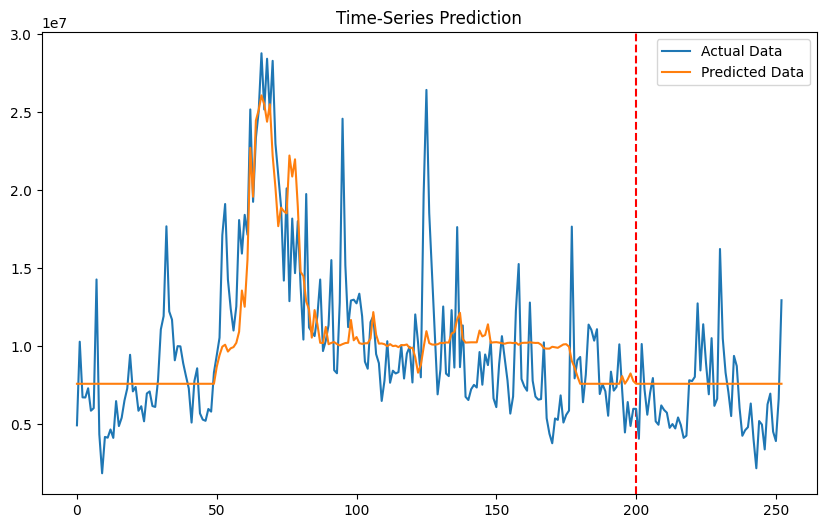

In [ ]:
train_predict = model(df_x_ss)
predicted = train_predict.data.numpy()

label_y = df_y_ms.data.numpy()

predicted = ms.inverse_transform(predicted)
label_y = ms.inverse_transform(label_y)
plt.figure(figsize=(10, 6))
plt.axvline(x=200, c='r', linestyle='--')

plt.plot(label_y, label='Actual Data')
plt.plot(predicted, label='Predicted Data')
plt.title('Time-Series Prediction')
plt.legend()
plt.show()

## 07. 양방항 RNN
#### 등장 배경 및 구조
* 기존 RNN은 과거 데이터만 참고하지만, 실제 문제에서는 **미래(이후) 시점의 데이터**에 정답 힌트가 있는 경우도 많음
* 이를 해결하기 위해 이전 시점과 이후 시점 데이터를 함께 활용하는 구조이며, RNN뿐만 아니라 LSTM과 GRU에도 동일하게 적용됨
* 하나의 출력을 예측하기 위해 **메모리 셀 두 개**를 사용함
  * 첫 번째 셀은 이전 시점 은닉 상태(forward states)를 전달받아 전방향 학습을 수행함
  * 두 번째 셀은 다음 시점 은닉 상태(backward states)를 전달받아 역방향 학습을 수행함
  * 두 셀에서 나온 결과값을 모두 결합해 출력층에서 최종 값을 예측함

#### 양방향 LSTM 구현 핵심 및 결과 (스타벅스 주가 예측)
* 파이토치 계층 정의 시 `bidirectional=True` 옵션만 추가하면 손쉽게 양방향 모델을 구현할 수 있음
* 전방향과 역방향 두 개의 계층을 동시에 사용하는 것과 같으므로, 단방향 모델과 달리 **초기 은닉 상태(`h_0`), 초기 셀 상태(`c_0`), 마지막 출력층(`fc`) 크기에 모두 `2`를 곱해주어야 함**
* 스타벅스 데이터셋 적용 결과 단방향 LSTM보다 실제 데이터와 예측 그래프가 유사하게 나타나며 더 나은 예측력을 보임

### 1)  양방향 RNN 구조



In [ ]:
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.autograd import Variable
from tqdm import tqdm_notebook
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

data = pd.read_csv('/content/080289//chap07/data/SBUX.csv')
print(data.dtypes)

data['Date'] = pd.to_datetime(data['Date'])
data.set_index('Date', inplace=True)
data['Volume'] = data['Volume'].astype(float)

X = data.iloc[:, :-1]
y = data.iloc[:, 5:6]

ms = MinMaxScaler()
ss = StandardScaler()

X_ss = ss.fit_transform(X)
y_ms = ms.fit_transform(y)

X_train = X_ss[:200, :]
X_test = X_ss[200:, :]
y_train = y_ms[:200, :]
y_test = y_ms[200:, :]

X_train_tensors = Variable(torch.Tensor(X_train))
X_test_tensors = Variable(torch.Tensor(X_test))

y_train_tensors = Variable(torch.Tensor(y_train))
y_test_tensors = Variable(torch.Tensor(y_test))

X_train_tensors_f = torch.reshape(X_train_tensors, (X_train_tensors.shape[0],
                                                   1, X_train_tensors.shape[1]))
X_test_tensors_f = torch.reshape(X_test_tensors, (X_test_tensors.shape[0],
                                                  1, X_test_tensors.shape[1]))

print("Training Shape", X_train_tensors_f.shape, y_train_tensors.shape)
print("Testing Shape", X_test_tensors_f.shape, y_test_tensors.shape)

Date          object
Open         float64
High         float64
Low          float64
Close        float64
Adj Close    float64
Volume         int64
dtype: object
Training Shape torch.Size([200, 1, 5]) torch.Size([200, 1])
Testing Shape torch.Size([53, 1, 5]) torch.Size([53, 1])


In [ ]:
class biLSTM(nn.Module):
  def __init__(self, num_classes, input_size, hidden_size, num_layers, seq_length):
    super(biLSTM, self).__init__()
    self.num_classes = num_classes
    self.num_layers = num_layers
    self.input_size = input_size
    self.hidden_size = hidden_size
    self.seq_length = seq_length

    self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size,
                        num_layers=num_layers, bidirectional=True, batch_first=True)
    self.fc = nn.Linear(hidden_size*2, num_classes)
    self.relu = nn.ReLU()

  def forward(self, x):
    h_0 = Variable(torch.zeros(self.num_layers*2, x.size(0), self.hidden_size))
    c_0 = Variable(torch.zeros(self.num_layers*2, x.size(0), self.hidden_size))
    out, _ = self.lstm(x, (h_0, c_0))
    out = self.fc(out[:, -1, :])
    out = self.relu(out)
    return out

In [ ]:
num_epochs = 1000
learning_rate = 0.0001

input_size = 5
hidden_size = 2
num_layers = 1
num_classes = 1
model = biLSTM(num_classes, input_size, hidden_size, num_layers, X_train_tensors_f.shape[1])

criterion = torch.nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

for epoch in range(num_epochs):
  outputs = model.forward(X_train_tensors_f)
  optimizer.zero_grad()

  loss = criterion(outputs, y_train_tensors)
  loss.backward()
  optimizer.step()
  if epoch % 100 == 0:
    print("Epoch: %d, loss: %1.5f" % (epoch, loss.item()))

Epoch: 0, loss: 0.14172
Epoch: 100, loss: 0.14172
Epoch: 200, loss: 0.14172
Epoch: 300, loss: 0.14172
Epoch: 400, loss: 0.14172
Epoch: 500, loss: 0.14172
Epoch: 600, loss: 0.14172
Epoch: 700, loss: 0.14172
Epoch: 800, loss: 0.14172
Epoch: 900, loss: 0.14172


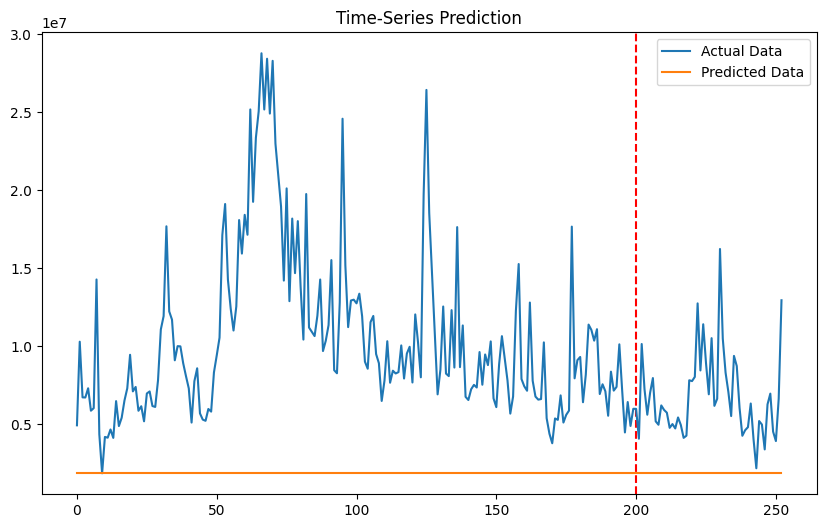

In [ ]:
df_x_ss = ss.transform(data.iloc[:, :-1])
df_y_ms = ms.transform(data.iloc[:, -1:])

df_x_ss = Variable(torch.Tensor(df_x_ss))
df_y_ms = Variable(torch.Tensor(df_y_ms))
df_x_ss = torch.reshape(df_x_ss, (df_x_ss.shape[0], 1, df_x_ss.shape[1]))

train_predict = model(df_x_ss)
predicted = train_predict.data.numpy()
label_y = df_y_ms.data.numpy()

predicted = ms.inverse_transform(predicted)
label_y = ms.inverse_transform(label_y)
plt.figure(figsize=(10, 6))
plt.axvline(x=200, c='r', linestyle='--')

plt.plot(label_y, label='Actual Data')
plt.plot(predicted, label='Predicted Data')
plt.title('Time-Series Prediction')
plt.legend()
plt.show()

시계열 분석 종합 결론
* 시계열 모델(RNN, LSTM, GRU, 양방향 모델) 중 특정 모델이 무조건 좋다고 단정할 수 없으므로, 주어진 데이터셋에 **다양한 모델을 적용하고 하이퍼파라미터를 튜닝하여 최적의 모델을 찾는 과정**이 중요함
* 모델 구현 자체보다 더 중요한 것은 **데이터 전처리**임 (실제 시계열 데이터는 단순 숫자보다 자연어 형태